In [1]:
import numpy as np
import time
from datetime import timedelta
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Flatten, Dense, Dropout, Input, BatchNormalization, GlobalAveragePooling1D
from keras.optimizers import Adam

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.regularizers import l2

from tensorflow.keras.layers import LSTM

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# CNN testing

In [24]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

# Load data
# Assuming you have the data in a CSV file
# df = pd.read_csv('your_data.csv')
# Since the dataframe is provided, I'll skip loading the data

# Split the data into features and target
#X = df.drop(columns=['target'])
#y = df['target']

# Standardize the data
#scaler = StandardScaler()
#X_scaled = scaler.fit_transform(X)

# Reshape the data for the Conv1D layer (samples, time steps, features)
#X_scaled = X_scaled.reshape(X_scaled.shape[0], X_scaled.shape[1], 1)

# Split into train and test sets
#X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
cnn_X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
cnn_X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
cnn_X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
# Build the CNN model
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(cnn_X_train.shape[1], 1)))
model.add(Conv1D(filters=64, kernel_size=3, activation='relu'))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
start_time = time.time()
history = model.fit(cnn_X_train, y_train, epochs=10, batch_size=32, validation_data=(cnn_X_val, y_val))
end_time = time.time()

print(f"CNN Model training time: {end_time - start_time:.2f} seconds")

# Evaluate the model
loss, accuracy = model.evaluate(cnn_X_train, y_test)
print(f"Test Loss: {loss}, Test Accuracy: {accuracy}")

# Making predictions
y_pred = model.predict(cnn_X_train)
y_pred_classes = (y_pred > 0.5).astype("int32")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)
print("Confusion Matrix:")
print(cm)

# Classification Report
cr = classification_report(y_test, y_pred_classes)
print("Classification Report:")
print(cr)


Epoch 1/10
206/206 [==============================] - 12s 36ms/step - loss: 0.8867 - accuracy: 0.6365 - val_loss: 0.5547 - val_accuracy: 0.6772
Epoch 2/10
206/206 [==============================] - 7s 33ms/step - loss: 0.5014 - accuracy: 0.7309 - val_loss: 0.4594 - val_accuracy: 0.7661
Epoch 3/10
206/206 [==============================] - 7s 32ms/step - loss: 0.4158 - accuracy: 0.7914 - val_loss: 0.3728 - val_accuracy: 0.8126
Epoch 4/10
206/206 [==============================] - 7s 33ms/step - loss: 0.3409 - accuracy: 0.8373 - val_loss: 0.3384 - val_accuracy: 0.8249
Epoch 5/10
206/206 [==============================] - 7s 32ms/step - loss: 0.2916 - accuracy: 0.8665 - val_loss: 0.2969 - val_accuracy: 0.8523
Epoch 6/10
206/206 [==============================] - 7s 32ms/step - loss: 0.2456 - accuracy: 0.8934 - val_loss: 0.2702 - val_accuracy: 0.8714
Epoch 7/10
206/206 [==============================] - 6s 31ms/step - loss: 0.2029 - accuracy: 0.9135 - val_loss: 0.2774 - val_accuracy: 0.871

ValueError: Data cardinality is ambiguous:
  x sizes: 6578
  y sizes: 1828
Make sure all arrays contain the same number of samples.

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_classes).ravel()

precision = precision_score(y_test, y_pred_classes)
recall = recall_score(y_test, y_pred_classes)
f1 = f1_score(y_test, y_pred_classes)
accuracy = accuracy_score(y_test, y_pred_classes)
specificity = tn / (tn + fp)

# ROC AUC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)

# Precision-Recall Curve
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred)
avg_precision = average_precision_score(y_test, y_pred)

CNN model:
Accuracy:  0.8845733041575492
Precision:  0.9342672413793104
Recall:  0.8525073746312685
F1 score:  0.8915167095115681
Specificity:  0.9247842170160296
AUC-ROC: 0.9588899922040477


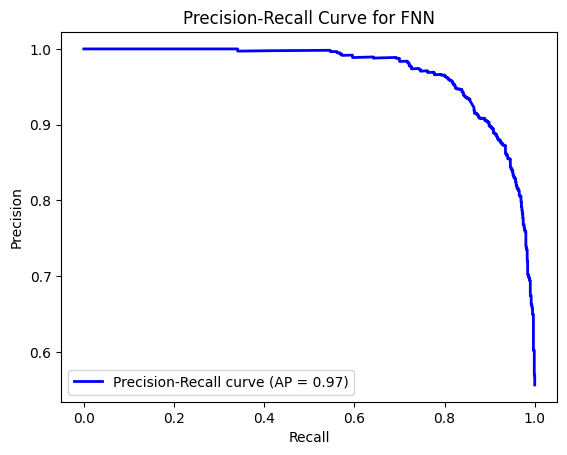

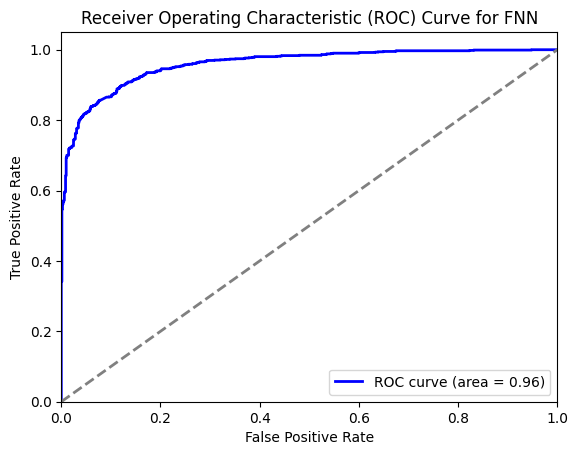

Confusion Matrix:
[[750  61]
 [150 867]]


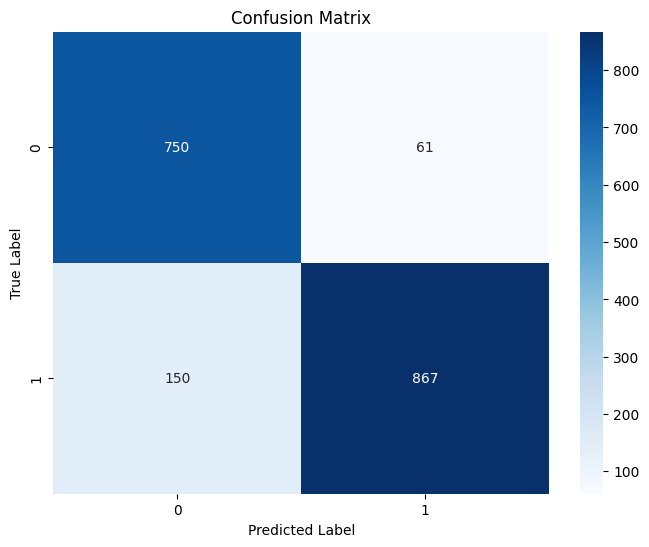

Classification report:
              precision    recall  f1-score   support

           0       0.83      0.92      0.88       811
           1       0.93      0.85      0.89      1017

    accuracy                           0.88      1828
   macro avg       0.88      0.89      0.88      1828
weighted avg       0.89      0.88      0.88      1828



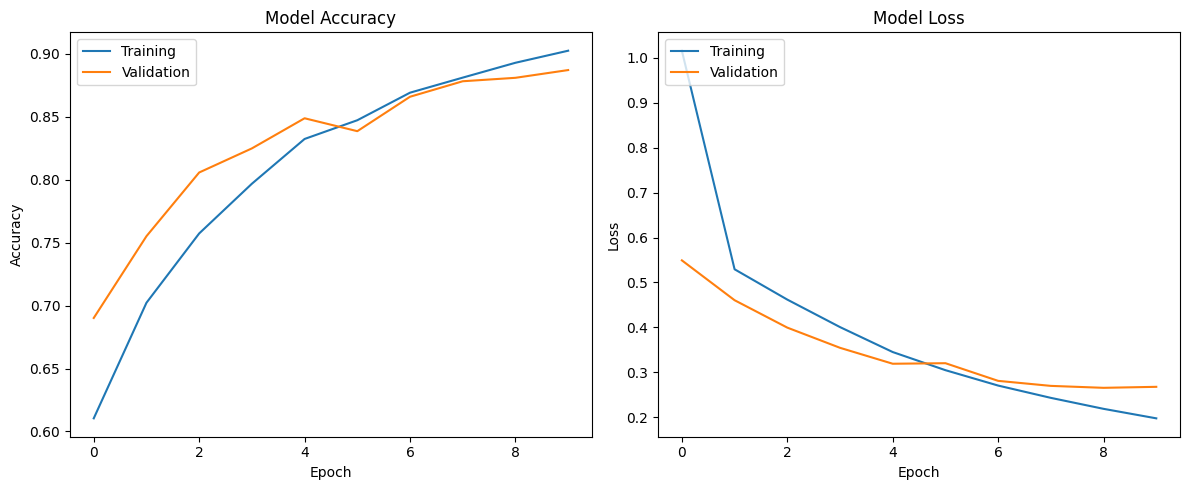

In [ ]:
print("CNN model:")
print("Accuracy: ", accuracy)
print("Precision: ", precision)
print("Recall: ", recall)
print("F1 score: ", f1)
print("Specificity: ", specificity)
print("AUC-ROC:", roc_auc)
#print("cnn_avg_precision: ", cnn_avg_precision)
#print("cnn_fpr: ", cnn_fpr)
#print("cnn_tpr: ", cnn_tpr)
#print("cnn_thresholds: ", cnn_thresholds)
#print("cnn_precision_vals: ", cnn_precision_vals)
#print("cnn_recall_vals: ", cnn_recall_vals)
#print("cnn_pr_thresholds: ", cnn_pr_thresholds)

# Plot Precision-Recall Curve
plt.figure()
plt.plot(recall_vals, precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for FNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for FNN')
plt.legend(loc="lower right")
plt.show()

print("Confusion Matrix:")
print(cm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

print("Classification report:")
print(cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(history)

# Data shtuff

In [157]:
path = r"/content/drive/MyDrive/datasets/withoutduplicates_combined_5sec.csv"
df = pd.read_csv(path)

In [ ]:
display(df)

In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
#shapes = pd.DataFrame({
#    "DataFrame": ["original", "1 sec", "3 secs", "5 secs", "7 secs"],
#    "Shape": [df0.shape, df1.shape, df3.shape, df5.shape, df7.shape],
#    "Total Elements": [df0.shape[0] * df0.shape[1], df1.shape[0] * df1.shape[1],
#                       df3.shape[0] * df3.shape[1], df5.shape[0] * df5.shape[1],
#                       df7.shape[0] * df7.shape[1]]
#})

#display(shapes)

,DataFrame,Shape,Total Elements
0,original,"(1540372, 43)",66235996
1,1 sec,"(77017, 841)",64771297
2,3 secs,"(25671, 2521)",64716591
3,5 secs,"(15402, 4201)",64703802
4,7 secs,"(11002, 5881)",64702762


In [158]:
target_distribution = df['target'].value_counts(normalize=True)
print(target_distribution)

target
1    0.544012
0    0.455988
Name: proportion, dtype: float64


In [159]:
def data_splitting(df):
    X = df.drop(columns = ["target"])
    y = df["target"]

    # Standardize the data
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42, stratify = y_train)


    # Standardize the data
    #scaler = StandardScaler()
    #X_train = scaler.fit_transform(X_train)
    #X_test = scaler.transform(X_test)
    #X_val = scaler.transform(X_val)

    #print(X_train.shape, y_train.shape)
    #print(X_val.shape, y_val.shape)
    #print(X_test.shape, y_test.shape)

    shapes_df = pd.DataFrame({
        'Set': ['Training Set', 'Validation Set', 'Test Set'],
        'Features Shape': [X_train.shape, X_val.shape, X_test.shape],
        'Labels Shape': [y_train.shape, y_val.shape, y_test.shape]
                })

    display(shapes_df)

    return X_train, y_train, X_val, y_val, X_test, y_test




In [160]:
X_train, y_train, X_val, y_val, X_test, y_test = data_splitting(df)

,Set,Features Shape,Labels Shape
0,Training Set,"(9209, 4300)","(9209,)"
1,Validation Set,"(1024, 4300)","(1024,)"
2,Test Set,"(2559, 4300)","(2559,)"


In [161]:
# Compute class weights
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))
print(class_weights_dict)

{0: 1.0965706120504881, 1: 0.919061876247505}


# Models

## FNN

In [162]:
def fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Assuming X_train is already defined
    input_shape = X_train.shape[1]

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # Build the model
    fnn_model = Sequential()
    fnn_model.add(Input(shape=(input_shape,)))
    fnn_model.add(Dense(512, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(256, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.5))
    fnn_model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(32, activation='relu'))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(1, activation='sigmoid'))
    fnn_model.summary()

    # Compile the model
    fnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    # Train the model
    start_time_fnn = time.time()
    fnn_history = fnn_model.fit(X_train, y_train
                        ,validation_data = (X_val, y_val)
                        ,epochs = 100
                        ,batch_size = 32
                        ,callbacks = [reduce_lr, early_stopping]
                        ,class_weight = class_weights_dict
                        )
    end_time_fnn = time.time()


    # Calculate the elapsed time
    training_time_fnn = end_time_fnn - start_time_fnn
    print(f"FNN Model training time: {training_time_fnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_fnn)
    milliseconds = int(training_time_fnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    # Predict on test data
    fnn_y_pred_prob = fnn_model.predict(X_test)
    fnn_y_pred = (fnn_y_pred_prob > 0.5).astype(int)


    # result calculation
    cm = confusion_matrix(y_test, fnn_y_pred)
    cr = classification_report(y_test, fnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, fnn_y_pred).ravel()

    precision = precision_score(y_test, fnn_y_pred)
    recall = recall_score(y_test, fnn_y_pred)
    f1 = f1_score(y_test, fnn_y_pred)
    accuracy = accuracy_score(y_test, fnn_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, fnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, fnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, fnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, fnn_y_pred_prob)

    return [fnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [163]:
[fnn_history, fnn_cm, fnn_cr, fnn_accuracy, fnn_precision, fnn_recall,
    fnn_f1, fnn_specificity, fnn_roc_auc, fnn_avg_precision, fnn_fpr, fnn_tpr, fnn_thresholds,
    fnn_precision_vals, fnn_recall_vals, fnn_pr_thresholds] = fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)


Model: "sequential_29"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_51 (Dense)            (None, 512)               2202112   
                                                                 
 dropout_106 (Dropout)       (None, 512)               0         
                                                                 
 dense_52 (Dense)            (None, 256)               131328    
                                                                 
 dropout_107 (Dropout)       (None, 256)               0         
                                                                 
 dense_53 (Dense)            (None, 128)               32896     
                                                                 
 dropout_108 (Dropout)       (None, 128)               0         
                                                                 
 dense_54 (Dense)            (None, 64)              

## CNN

In [164]:
def cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Reshape data for Conv1D
    cnn_X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    cnn_X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
    cnn_X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))


    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)


    # Build and train the CNN model
    cnn_model = Sequential([
        Conv1D(filters=64, kernel_size=7, activation='relu', input_shape=(cnn_X_train.shape[1], 1), kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.3),

        Conv1D(filters=64, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        #GlobalMaxPooling1D(),
        Dropout(0.6),

        #Conv1D(filters=128, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.6),
        #GlobalMaxPooling1D(),

        Flatten(),
        Dense(128, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.6),
        #Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        #Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        Dense(32, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    cnn_model.summary()

    cnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    start_time_cnn = time.time()
    cnn_history = cnn_model.fit(cnn_X_train, y_train
                                ,validation_data=(cnn_X_val, y_val)
                                ,epochs=100
                                ,batch_size=32
                                ,callbacks=[early_stopping, reduce_lr]
                                ,class_weight = class_weights_dict
                                )
    end_time_cnn = time.time()

    # Calculate the elapsed time
    training_time_cnn = end_time_cnn - start_time_cnn
    print(f"FNN Model training time: {training_time_cnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_cnn)
    milliseconds = int(training_time_cnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")

    # Evaluate CNN model
    cnn_y_pred_prob = cnn_model.predict(cnn_X_test)
    cnn_y_pred = (cnn_y_pred_prob > 0.5).astype(int)

    # result calculation
    cm = confusion_matrix(y_test, cnn_y_pred)
    cr = classification_report(y_test, cnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, cnn_y_pred).ravel()

    precision = precision_score(y_test, cnn_y_pred)
    recall = recall_score(y_test, cnn_y_pred)
    f1 = f1_score(y_test, cnn_y_pred)
    accuracy = accuracy_score(y_test, cnn_y_pred)
    specificity = tn / (tn + fp)


    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, cnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, cnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, cnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, cnn_y_pred_prob)

    return [cnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [165]:
#cnn model
[cnn_history, cnn_cm, cnn_cr, cnn_accuracy, cnn_precision, cnn_recall,
    cnn_f1, cnn_specificity, cnn_roc_auc, cnn_avg_precision, cnn_fpr, cnn_tpr, cnn_thresholds,
    cnn_precision_vals, cnn_recall_vals, cnn_pr_thresholds] = cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

Model: "sequential_30"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_17 (Conv1D)          (None, 4294, 64)          512       
                                                                 
 dropout_111 (Dropout)       (None, 4294, 64)          0         
                                                                 
 conv1d_18 (Conv1D)          (None, 4288, 64)          28736     
                                                                 
 dropout_112 (Dropout)       (None, 4288, 64)          0         
                                                                 
 dropout_113 (Dropout)       (None, 4288, 64)          0         
                                                                 
 flatten_7 (Flatten)         (None, 274432)            0         
                                                                 
 dense_57 (Dense)            (None, 128)             

## LSTM

In [166]:
def lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):

    X_train_lstm = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
    X_test_lstm = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])
    X_val_lstm = X_val.reshape(X_val.shape[0], 1, X_val.shape[1])

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # LSTM
    model = Sequential()
    model.add(LSTM(units=256, return_sequences=True, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
    model.add(Dropout(0.3))
    model.add(BatchNormalization())

    model.add(LSTM(units=128, return_sequences=True))
    model.add(Dropout(0.3))
    model.add(BatchNormalization())

    model.add(LSTM(units=64, return_sequences=True))
    model.add(Dropout(0.5))
    model.add(BatchNormalization())

    model.add(LSTM(units=32, return_sequences=True))
    model.add(Dropout(0.5))
    #model.add(BatchNormalization())

    model.add(LSTM(units=16, return_sequences=True))
    model.add(Dropout(0.6))
    model.add(BatchNormalization())

    model.add(LSTM(units=8))
    model.add(Dropout(0.6))
    model.add(BatchNormalization())

    model.add(Dense(units=1, activation='sigmoid'))

    model.summary()

    # Compile the model
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])  # Adjust loss and metrics as per your task

    # Train the model
    start_time_lstm = time.time()
    lstm_history = model.fit(X_train_lstm, y_train
                            ,epochs=100
                            ,batch_size=32
                            ,validation_data=(X_val_lstm, y_val)
                            ,callbacks = [reduce_lr, early_stopping]
                            ,class_weight = class_weights_dict
                             )
    end_time_lstm = time.time()

    # Calculate the elapsed time
    training_time_lstm = end_time_lstm - start_time_lstm
    print(f"FNN Model training time: {training_time_lstm:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_lstm)
    milliseconds = int(training_time_lstm * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    lstm_y_pred_prob = model.predict(X_test_lstm)
    lstm_y_pred = (lstm_y_pred_prob > 0.5).astype(int)


    # result calculation
    cm = confusion_matrix(y_test, lstm_y_pred)
    cr = classification_report(y_test, lstm_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, lstm_y_pred).ravel()

    precision = precision_score(y_test, lstm_y_pred)
    recall = recall_score(y_test, lstm_y_pred)
    f1 = f1_score(y_test, lstm_y_pred)
    accuracy = accuracy_score(y_test, lstm_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, lstm_y_pred_prob)
    roc_auc = roc_auc_score(y_test, lstm_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, lstm_y_pred_prob)
    avg_precision = average_precision_score(y_test, lstm_y_pred_prob)

    return [lstm_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [167]:
#lstm model
[lstm_history, lstm_cm, lstm_cr, lstm_accuracy, lstm_precision, lstm_recall,
    lstm_f1, lstm_specificity, lstm_roc_auc, lstm_avg_precision, lstm_fpr, lstm_tpr, lstm_thresholds,
    lstm_precision_vals, lstm_recall_vals, lstm_pr_thresholds] = lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

Model: "sequential_31"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_68 (LSTM)              (None, 1, 256)            4666368   
                                                                 
 dropout_116 (Dropout)       (None, 1, 256)            0         
                                                                 
 batch_normalization_52 (Ba  (None, 1, 256)            1024      
 tchNormalization)                                               
                                                                 
 lstm_69 (LSTM)              (None, 1, 128)            197120    
                                                                 
 dropout_117 (Dropout)       (None, 1, 128)            0         
                                                                 
 batch_normalization_53 (Ba  (None, 1, 128)            512       
 tchNormalization)                                   

# Results

## FNN

In [168]:
print("FNN model:")
print("Accuracy: ", fnn_accuracy)
print("Precision: ", fnn_precision)
print("Recall: ", fnn_recall)
print("F1 score: ", fnn_f1)
print("Specificity: ", fnn_specificity)
print("AUC-ROC:", fnn_roc_auc)

FNN model:
Accuracy:  0.8147713950762017
Precision:  0.9150090415913201
Recall:  0.7270114942528736
F1 score:  0.8102481985588471
Specificity:  0.919451585261354
AUC-ROC: 0.9044466359365304


In [169]:
print("fnn_avg_precision: ", fnn_avg_precision)
print("fnn_fpr: ", fnn_fpr)
print("fnn_tpr: ", fnn_tpr)
print("fnn_thresholds: ", fnn_thresholds)
print("fnn_precision_vals: ", fnn_precision_vals)
print("fnn_recall_vals: ", fnn_recall_vals)
print("fnn_pr_thresholds: ", fnn_pr_thresholds)

fnn_avg_precision:  0.9248187097654812
fnn_fpr:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 8.56898029e-04
 8.56898029e-04 1.71379606e-03 1.71379606e-03 2.57069409e-03
 2.57069409e-03 3.42759212e-03 3.42759212e-03 5.14138817e-03
 5.14138817e-03 5.99828620e-03 5.99828620e-03 6.85518423e-03
 6.85518423e-03 7.71208226e-03 7.71208226e-03 8.56898029e-03
 8.56898029e-03 1.02827763e-02 1.02827763e-02 1.11396744e-02
 1.11396744e-02 1.19965724e-02 1.19965724e-02 1.28534704e-02
 1.28534704e-02 1.37103685e-02 1.37103685e-02 1.45672665e-02
 1.45672665e-02 1.54241645e-02 1.54241645e-02 1.71379606e-02
 1.71379606e-02 1.79948586e-02 1.79948586e-02 1.88517566e-02
 1.88517566e-02 1.97086547e-02 1.970

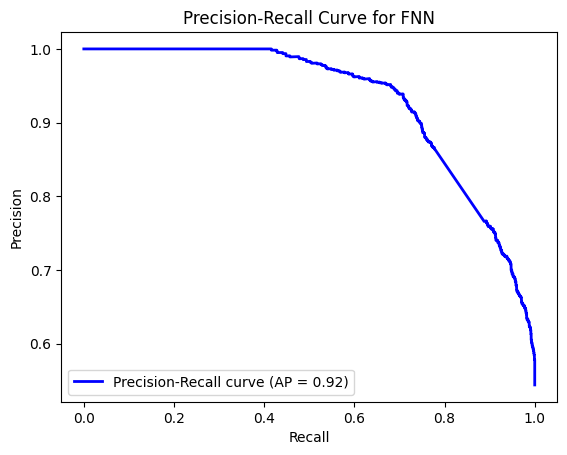

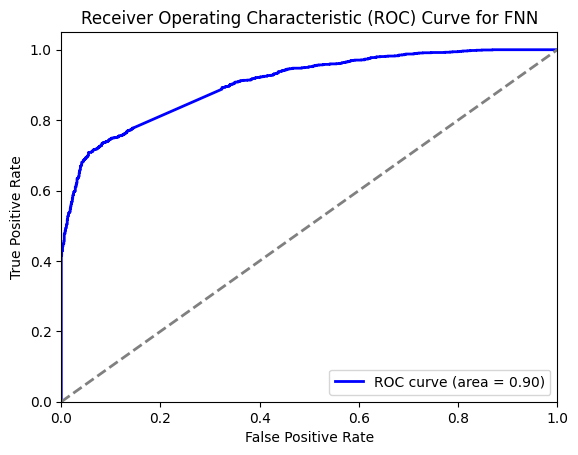

In [170]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(fnn_recall_vals, fnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {fnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for FNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(fnn_fpr, fnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {fnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for FNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[1073   94]
 [ 380 1012]]


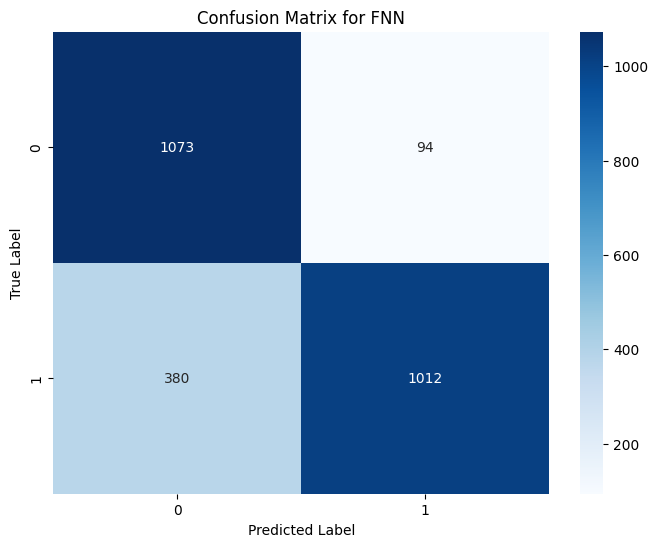

Classification report:
              precision    recall  f1-score   support

           0       0.74      0.92      0.82      1167
           1       0.92      0.73      0.81      1392

    accuracy                           0.81      2559
   macro avg       0.83      0.82      0.81      2559
weighted avg       0.83      0.81      0.81      2559



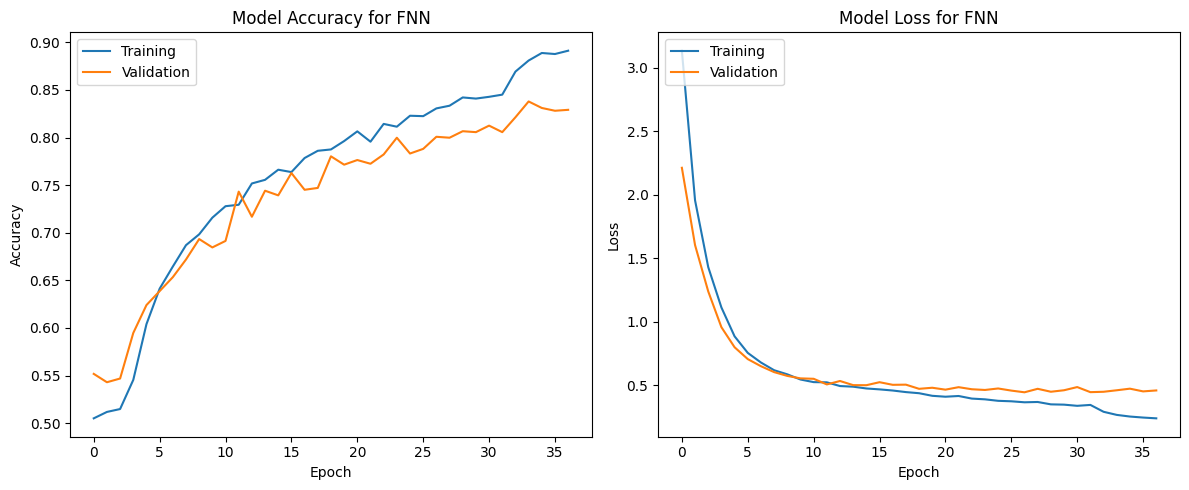

In [171]:
print("Confusion Matrix:")
print(fnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(fnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for FNN')
plt.show()

print("Classification report:")
print(fnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(fnn_history)

## CNN

In [172]:
print("CNN model:")
print("Accuracy: ", cnn_accuracy)
print("Precision: ", cnn_precision)
print("Recall: ", cnn_recall)
print("F1 score: ", cnn_f1)
print("Specificity: ", cnn_specificity)
print("AUC-ROC:", cnn_roc_auc)

CNN model:
Accuracy:  0.9144196951934349
Precision:  0.9174377224199288
Recall:  0.9260057471264368
F1 score:  0.9217018233821952
Specificity:  0.9005998286203942
AUC-ROC: 0.9771967861399207


In [173]:
print("cnn_avg_precision: ", cnn_avg_precision)
print("cnn_fpr: ", cnn_fpr)
print("cnn_tpr: ", cnn_tpr)
print("cnn_thresholds: ", cnn_thresholds)
print("cnn_precision_vals: ", cnn_precision_vals)
print("cnn_recall_vals: ", cnn_recall_vals)
print("cnn_pr_thresholds: ", cnn_pr_thresholds)

cnn_avg_precision:  0.9830915815012475
cnn_fpr:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 8.56898029e-04 8.56898029e-04 1.71379606e-03
 1.71379606e-03 2.57069409e-03 2.57069409e-03 3.42759212e-03
 3.42759212e-03 4.28449015e-03 4.28449015e-03 5.14138817e-03
 5.14138817e-03 5.99828620e-03 5.99828620e-03 6.85518423e-03
 6.85518423e-03 7.71208226e-03 7.71208226e-03 8.56898029e-03
 8.56898029e-03 9.42587832e-03 9.42587832e-03 1.02827763e-02
 1.02827763e-02 1.11396744e-02 1.11396744e-02 1.19965724e-02
 1.19965724e-02 1.28534704e-02 1.28534704e-02 1.37103685e-02
 1.37103685e-02 1.54241645e-02 1.54241645e-02 1.62810626e-02
 1.62810626e-02 1.71379606e-02 1.713

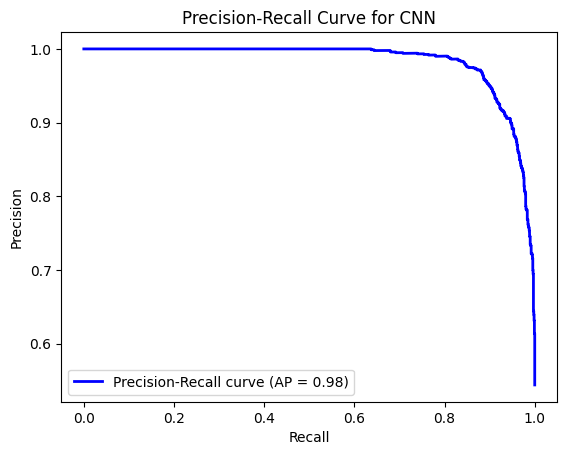

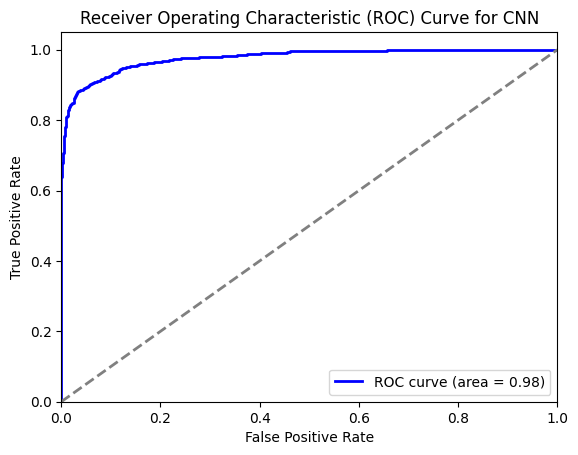

In [174]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(cnn_recall_vals, cnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {cnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for CNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(cnn_fpr, cnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {cnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[1051  116]
 [ 103 1289]]


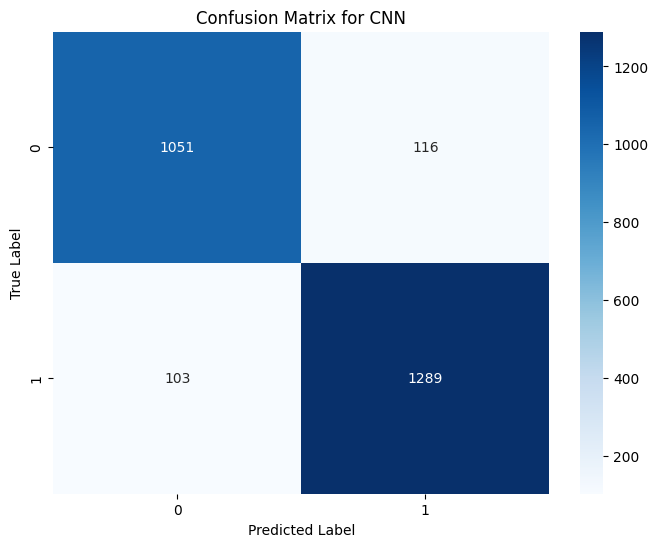

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.90      0.91      1167
           1       0.92      0.93      0.92      1392

    accuracy                           0.91      2559
   macro avg       0.91      0.91      0.91      2559
weighted avg       0.91      0.91      0.91      2559



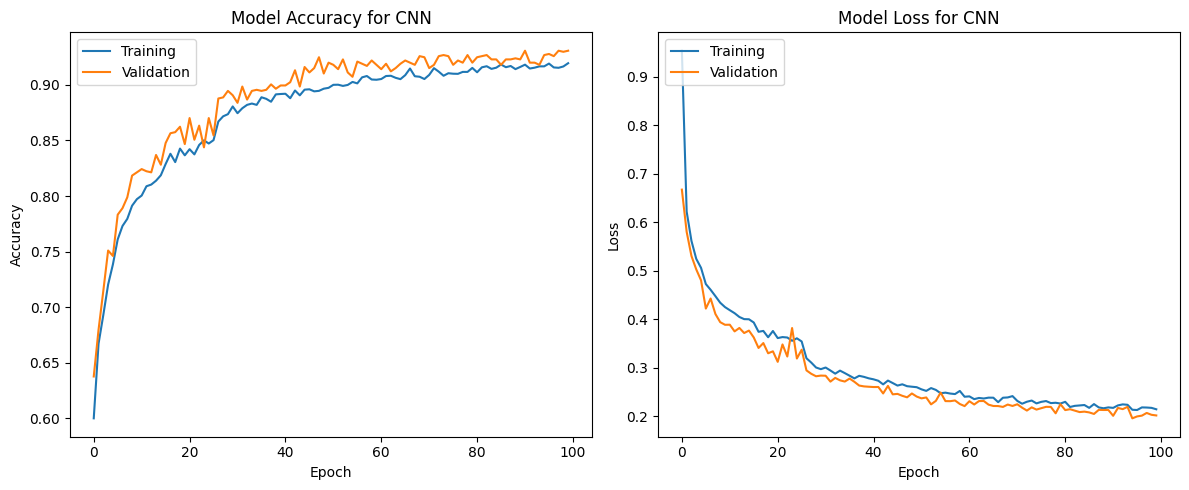

In [175]:
print("Confusion Matrix:")
print(cnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(cnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for CNN')
plt.show()

print("Classification report:")
print(cnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(cnn_history)

## LSTM

In [176]:
print("LSTM model:")
print("Accuracy: ", lstm_accuracy)
print("Precision: ", lstm_precision)
print("Recall: ", lstm_recall)
print("F1 score: ", lstm_f1)
print("Specificity: ", lstm_specificity)
print("AUC-ROC:", lstm_roc_auc)

LSTM model:
Accuracy:  0.8937084798749512
Precision:  0.9354587869362364
Recall:  0.8642241379310345
F1 score:  0.8984316654219566
Specificity:  0.9288774635818338
AUC-ROC: 0.9597750396438456


In [177]:
print("lstm_avg_precision: ", lstm_avg_precision)
print("lstm_fpr: ", lstm_fpr)
print("lstm_tpr: ", lstm_tpr)
print("lstm_thresholds: ", lstm_thresholds)
print("lstm_precision_vals: ", lstm_precision_vals)
print("lstm_recall_vals: ", lstm_recall_vals)
print("lstm_pr_thresholds: ", lstm_pr_thresholds)

lstm_avg_precision:  0.968772264300538
lstm_fpr:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 8.56898029e-04 8.56898029e-04 1.71379606e-03
 1.71379606e-03 2.57069409e-03 2.57069409e-03 3.42759212e-03
 3.42759212e-03 4.28449015e-03 4.28449015e-03 5.14138817e-03
 5.14138817e-03 5.99828620e-03 5.99828620e-03 6.85518423e-03
 6.85518423e-03 7.71208226e-03 7.71208226e-03 8.56898029e-03
 8.56898029e-03 9.42587832e-03 9.42587832e-03 1.02827763e-02
 1.02827763e-02 1.11396744e-02 1.11396744e-02 1.19965724e-02
 1.19965724e-02 1.28534704e-02 1.28534704e-02 1.37103685e-02
 1.37103685e-02 1.45672665e-02 1.45672665e-02 1.54241645e-02
 1.54241645e-02 1.62810626e-02 1.62810626e-02 1.71379606e-02
 1.71379606e-02 1.79948586e-02 1.79

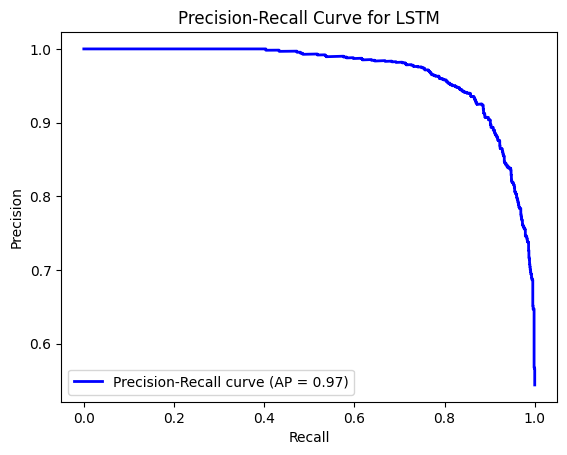

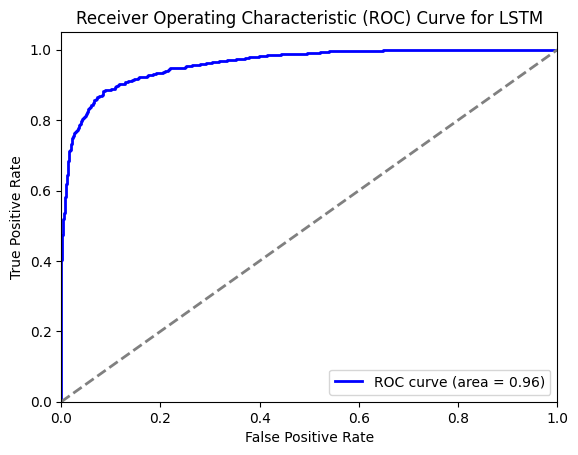

In [178]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(lstm_recall_vals, lstm_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for LSTM')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(lstm_fpr, lstm_tpr, color='blue', lw=2, label=f'ROC curve (area = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for LSTM')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[1084   83]
 [ 189 1203]]


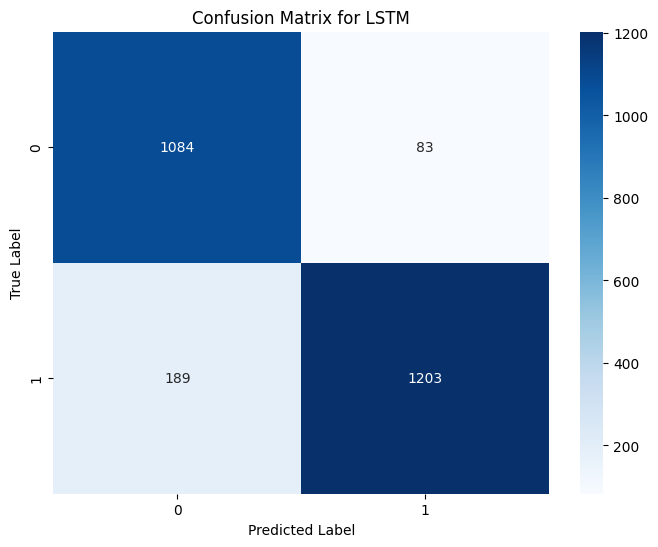

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.93      0.89      1167
           1       0.94      0.86      0.90      1392

    accuracy                           0.89      2559
   macro avg       0.89      0.90      0.89      2559
weighted avg       0.90      0.89      0.89      2559



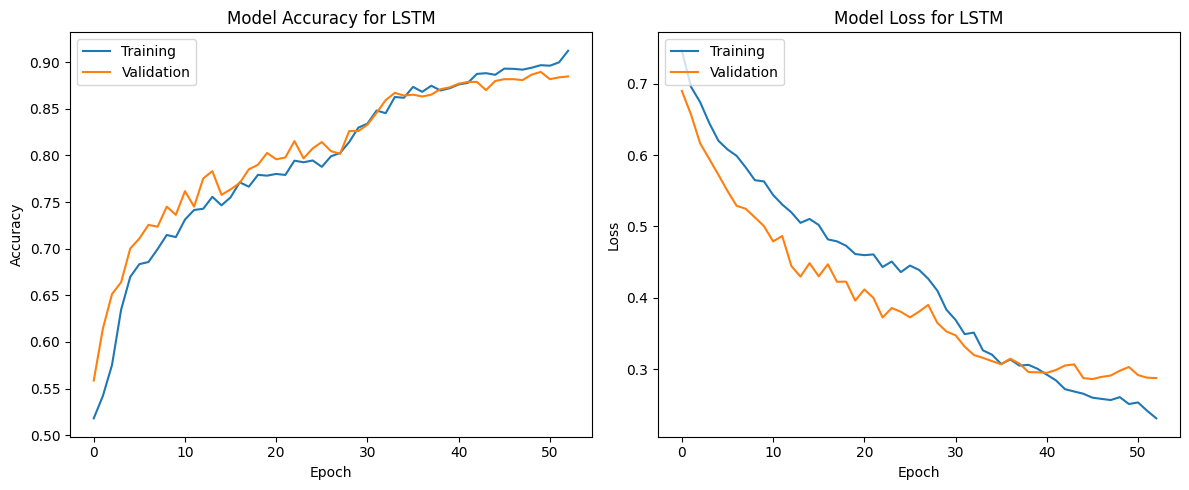

In [179]:
print("Confusion Matrix:")
print(lstm_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(lstm_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for LSTM')
plt.show()

print("Classification report:")
print(lstm_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(lstm_history)

## Combined

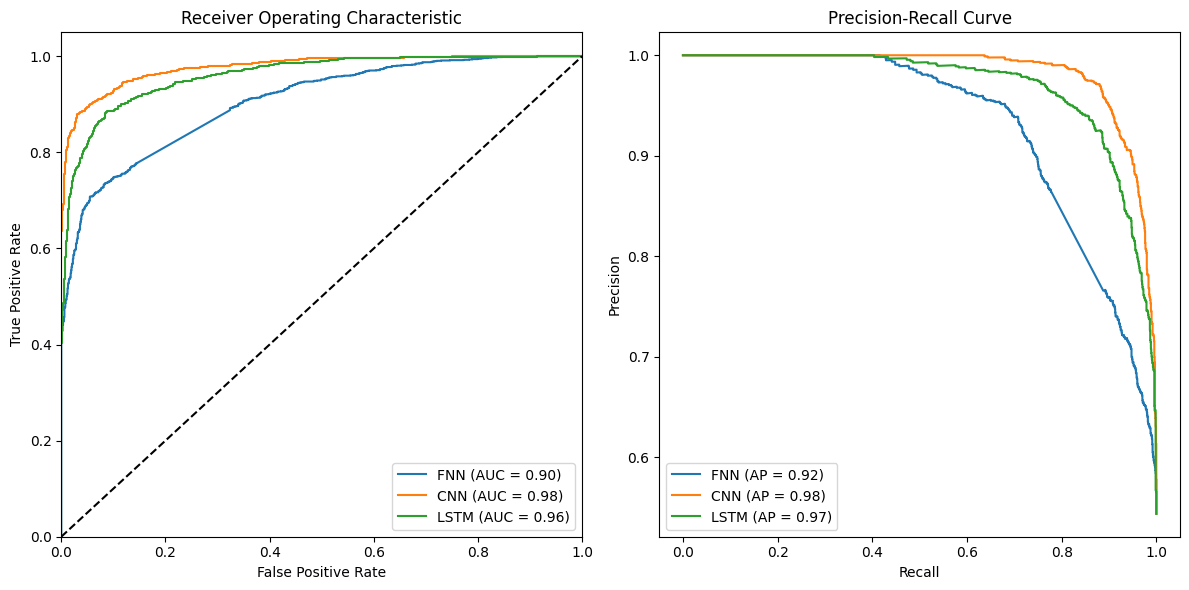

In [180]:
# Plot ROC curves
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(fnn_fpr, fnn_tpr, label=f'FNN (AUC = {fnn_roc_auc:.2f})')
plt.plot(cnn_fpr, cnn_tpr, label=f'CNN (AUC = {cnn_roc_auc:.2f})')
plt.plot(lstm_fpr, lstm_tpr, label=f'LSTM (AUC = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")

# Plot Precision-Recall curves
plt.subplot(1, 2, 2)
plt.plot(fnn_recall_vals, fnn_precision_vals, label=f'FNN (AP = {fnn_avg_precision:.2f})')
plt.plot(cnn_recall_vals, cnn_precision_vals, label=f'CNN (AP = {cnn_avg_precision:.2f})')
plt.plot(lstm_recall_vals, lstm_precision_vals, label=f'LSTM (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()

In [156]:
%%shell
jupyter nbconvert --to html /content/stress_detection_7secs.ipynb

[NbConvertApp] Converting notebook /content/stress_detection_7secs.ipynb to html
[NbConvertApp] Writing 1661120 bytes to /content/stress_detection_7secs.html
